# Preparation et exploration des données

In [207]:
# Import packages
import logging
from datetime import date,datetime
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import numpy as np
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import langid
from collections import Counter

import torch
from transformers import BertTokenizer, BertModel
from tqdm import tqdm


ModuleNotFoundError: No module named 'transformers'

In [178]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## Chargement des données

In [179]:

X_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\X_train_update.csv",sep=",", encoding="utf-8", index_col=0)
y_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\Y_train.csv",sep=",", encoding="utf-8", index_col=0)
# liste des chemins d'accès aux images

data_train = pd.concat([X_train, y_train], axis=1)

images_path = os.path.join(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train")
image_names = [name for name in os.listdir(images_path)]
print(f"Nombre d'images : {len(image_names)}\nExemple de nom d'image : {image_names[0]}\n")

print("5 premièeres lignes de X_train :")
print(X_train.head())

print("Description de y_train :")
print(y_train.describe())

Nombre d'images : 84916
Exemple de nom d'image : image_1000076039_product_580161.jpg

5 premièeres lignes de X_train :
                                         designation  \
0  Olivia: Personalisiertes Notizbuch / 150 Seite...   
1  Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...   
2  Grand Stylet Ergonomique Bleu Gamepad Nintendo...   
3  Peluche Donald - Europe - Disneyland 2000 (Mar...   
4                               La Guerre Des Tuques   

                                         description   productid     imageid  
0                                                NaN  3804725264  1263597046  
1                                                NaN   436067568  1008141237  
2  PILOT STYLE Touch Pen de marque Speedlink est ...   201115110   938777978  
3                                                NaN    50418756   457047496  
4  Luc a des id&eacute;es de grandeur. Il veut or...   278535884  1077757786  
Description de y_train :
        prdtypecode
count  84916.000000
mean 

In [180]:
# Création d'un DataFrame pour les images avec les ids extraits des noms de fichiers
image_list = []
regex = re.compile(r'image_(\d+)_product_(\d+)\.jpg')
for name in image_names:
    match = regex.match(name)
    if match:
        img_id = int(match.group(1))
        product_id = int(match.group(2))
        image_list.append({
            'image_name': name,
            'imageid': int(match.group(1)),
            'productid': int(match.group(2))
        })

image_df = pd.DataFrame(image_list)
print(image_df.head(10))
print(f"\nNombre d'images dans image_df : {len(image_df)} comparé au nombre dans la liste de base {len(image_names)}")

                               image_name     imageid  productid
0     image_1000076039_product_580161.jpg  1000076039     580161
1  image_1000089455_product_348990858.jpg  1000089455  348990858
2  image_1000092894_product_353108104.jpg  1000092894  353108104
3  image_1000093804_product_343306951.jpg  1000093804  343306951
4  image_1000095646_product_344209267.jpg  1000095646  344209267
5  image_1000095647_product_148177050.jpg  1000095647  148177050
6  image_1000099971_product_352683003.jpg  1000099971  352683003
7  image_1000100220_product_352601770.jpg  1000100220  352601770
8  image_1000222973_product_351172420.jpg  1000222973  351172420
9  image_1000228891_product_355017693.jpg  1000228891  355017693

Nombre d'images dans image_df : 84916 comparé au nombre dans la liste de base 84916


In [181]:
data_train = pd.merge(data_train,image_df,on=['productid', 'imageid'],how='left')
data_train["designation"] = data_train["designation"].str.lower()
data_train["description"] = data_train["description"].str.lower()

print(data_train.head())

                                         designation  \
0  olivia: personalisiertes notizbuch / 150 seite...   
1  journal des arts (le) n° 133 du 28/09/2001 - l...   
2  grand stylet ergonomique bleu gamepad nintendo...   
3  peluche donald - europe - disneyland 2000 (mar...   
4                               la guerre des tuques   

                                         description   productid     imageid  \
0                                                NaN  3804725264  1263597046   
1                                                NaN   436067568  1008141237   
2  pilot style touch pen de marque speedlink est ...   201115110   938777978   
3                                                NaN    50418756   457047496   
4  luc a des id&eacute;es de grandeur. il veut or...   278535884  1077757786   

   prdtypecode                               image_name  
0           10  image_1263597046_product_3804725264.jpg  
1         2280   image_1008141237_product_436067568.jpg  
2       

In [182]:
#Nombre de Nan dans chaque colonne
print("Pourcentage de Nan dans chaque colonne :")
print(data_train.isna().sum()/len(data_train))

Pourcentage de Nan dans chaque colonne :
designation    0.000000
description    0.350935
productid      0.000000
imageid        0.000000
prdtypecode    0.000000
image_name     0.000000
dtype: float64


In [210]:
def detect_me(text):
    langid.set_languages(['fr', 'en', 'es', 'de',])
    if pd.isna(text) or len(str(text)) < 5:
        return 'unknown'
    lang, _ = langid.classify(str(text))
    return lang

data_train['language'] = data_train['designation'].apply(detect_me)

In [211]:
with pd.option_context('display.max_rows', None):
    print(data_train['language'].value_counts())

language
fr    68748
en    12148
es     2363
de     1657
Name: count, dtype: int64


In [213]:
print(data_train[data_train['language'] == 'de']['designation'].head(20))

0      olivia: personalisiertes notizbuch / 150 seite...
6             christof e: bildungsprozessen auf der spur
35     decoration de noel christmas snowman kitchen t...
120           trampoline berg elite inground rouge 430cm
131      dr. mercurius' heilsame reise zum planeten erde
155    scott mitchell - cincinnati bengals - 2001 upp...
382    zöllner schlafsack mit applikation sternchen b...
396      les schtroumpfs - schtroumpf  toothbrush  20064
400            shardwrack spines 64-04 - warhammer 40000
449        army men in space jeu pc big box grosse boite
460                            ich du und die ganze welt
513                 sherwood g: pedigree register vol. 2
571                    collier - zelda - charm windwaker
585          beach toys la reine des neiges - kick board
675    vinyles 33t--coffret 4lp--richard wagner : tan...
683    dahle tableau blanc slim board basic ft 60 x 9...
686                         conviction - forteresse - vf
753    superman - t-shirt sacri

## Repartition des classes

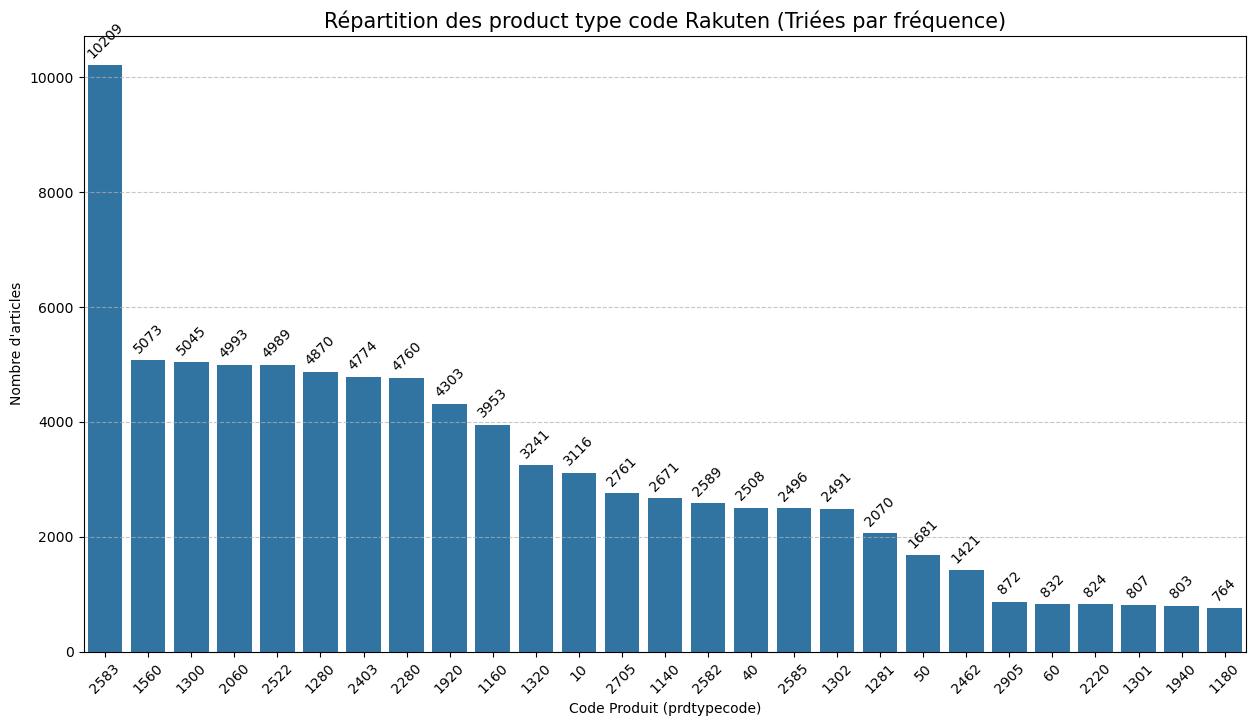

In [154]:
plt.figure(figsize=(15, 8))
order = data_train["prdtypecode"].value_counts().index
ax = sns.countplot(data=data_train, x="prdtypecode", order=order)
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10, rotation=45)
plt.title('Répartition des product type code Rakuten (Triées par fréquence)', fontsize=15)
plt.xticks(rotation=45) 
plt.xlabel('Code Produit (prdtypecode)')
plt.ylabel('Nombre d\'articles')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Frequence des mots

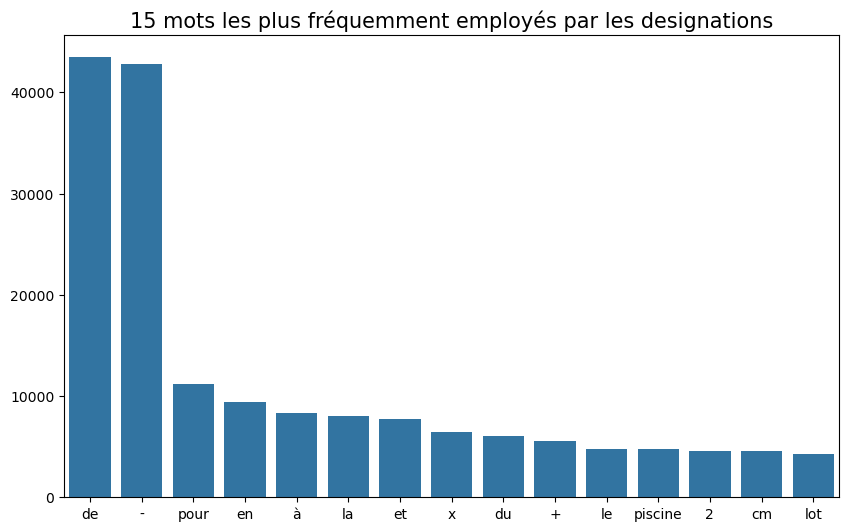

In [155]:
def frequency_words(data_train):
    chaine = ' '.join(i.lower() for i in data_train.designation)

    dico = Counter(chaine.split())
    mots = [m[0] for m in dico.most_common(15)]
    freq = [m[1] for m in dico.most_common(15)]

    plt.figure(figsize= (10,6))
    sns.barplot(x=mots, y=freq)
    plt.title('15 mots les plus fréquemment employés par les designations', fontsize=15)

frequency_words(data_train)

## suppression des stop word

In [156]:
stop_words_fr = set(stopwords.words('french'))
stop_words_en = set(stopwords.words('english'))
all_stopwords = stop_words_fr | stop_words_en
print(f"Nombre de stopwords : {len(all_stopwords)}, en français : {len(stop_words_fr)}, en anglais : {len(stop_words_en)}\n")
print(all_stopwords)

Nombre de stopwords : 346, en français : 157, en anglais : 198

{'eux', "hadn't", 'be', 'once', 'until', 'soit', 'sois', 'further', 'étante', 'm', 'most', 's', 'weren', 'étais', 'about', 'tu', 'not', "won't", 'elle', 'vous', 'which', 'against', "weren't", 'aurez', 'nor', "you'd", 'out', 'ours', 'at', 'votre', 'avait', 'to', 'ne', 'won', 'sommes', 'had', 'each', 'with', 'couldn', "they're", "he'd", 'haven', 'ayants', "we've", 'fusse', 'll', 'your', 'no', 'these', 'serons', 'sur', 'il', 'eusses', "that'll", 'des', 'étiez', 'during', 'ou', 'étants', 'shouldn', 'ce', 'off', "she's", 'avaient', "i'm", 'didn', "i'd", 'un', 'ai', 'we', 'soyons', 'do', 'o', 'eue', 'te', 'soyez', 'their', 'there', 'in', 'mightn', 'this', 'myself', 'theirs', 'aurais', 'avais', 'just', 'moi', 'have', 'auront', "they'll", 'serai', 'dans', 'est', 'ayantes', "haven't", 'again', 'for', 'mes', 'l', 'other', "i've", "it'd", 'my', 'been', 'from', 'ils', 'j', 'ont', 'tes', 'am', 'because', 'some', 'it', 'isn', "mustn't",

In [157]:
new_stop_words = [",", ".", "``", "@", "*", "(", ")", "...", "!", "?", "-", "_", ">", "<", ":", "/", "=", "--", "©", "~", ";", "\\", "\\\\","x","+",]
all_stopwords.update(new_stop_words)
print(f"Nombre total de stopwords après ajout de la ponctuation : {len(all_stopwords)}\n")
print(all_stopwords)

Nombre total de stopwords après ajout de la ponctuation : 371

{'eux', "hadn't", 'be', 'once', 'until', 'soit', 'sois', 'further', 'étante', 'm', 'most', 's', 'weren', 'étais', 'about', 'tu', 'not', "won't", 'elle', 'vous', 'which', 'against', "weren't", 'aurez', 'nor', "you'd", 'out', 'ours', '~', 'at', 'votre', 'avait', 'to', 'ne', 'won', 'sommes', 'had', 'each', 'with', 'couldn', "they're", "he'd", 'haven', 'ayants', "we've", 'fusse', 'll', 'your', 'no', 'these', 'serons', 'sur', 'il', 'eusses', "that'll", '...', 'des', 'étiez', 'during', 'ou', 'étants', 'shouldn', 'ce', 'off', "she's", 'avaient', "i'm", 'didn', "i'd", 'un', 'ai', 'we', 'soyons', 'do', 'o', 'eue', 'te', 'soyez', 'their', '@', '+', 'there', 'in', 'mightn', 'this', 'myself', 'theirs', 'aurais', 'avais', 'just', 'moi', 'have', 'auront', ';', "they'll", '>', 'serai', 'dans', 'est', 'ayantes', "haven't", 'again', 'for', 'mes', 'l', 'other', "i've", "it'd", 'my', 'been', 'from', 'ils', 'j', 'ont', 'tes', 'am', 'because', 

In [158]:
# Tokenisation de la colonne designation
data_train["designation"] = data_train["designation"].apply(word_tokenize)
data_train["designation"].head()

0    [olivia, :, personalisiertes, notizbuch, /, 15...
1    [journal, des, arts, (, le, ), n°, 133, du, 28...
2    [grand, stylet, ergonomique, bleu, gamepad, ni...
3    [peluche, donald, -, europe, -, disneyland, 20...
4                            [la, guerre, des, tuques]
Name: designation, dtype: object

In [159]:
def stop_words_filtering(mots,stop_words) : 
    
    tokens = []
    for mot in mots:
        if mot not in stop_words:
            tokens.append(mot)
    return tokens

In [ ]:
# Mise à jour de la colonne designation en supprimant les stopwords
data_train['designation'] = data_train['designation'].apply(lambda x: stop_words_filtering(x, all_stopwords))
data_train['designation'].head()

0    [olivia, personalisiertes, notizbuch, 150, sei...
1    [journal, arts, n°, 133, 28/09/2001, l'art, ma...
2    [grand, stylet, ergonomique, bleu, gamepad, ni...
3    [peluche, donald, europe, disneyland, 2000, ma...
4                                     [guerre, tuques]
Name: designation, dtype: object

In [162]:
for i in range (0, len(data_train['designation'])):
    data_train.loc[i, 'designation'] = ' '.join(data_train.loc[i, 'designation'])

0    olivia personalisiertes notizbuch 150 seiten p...
1    journal arts n° 133 28/09/2001 l'art marche sa...
2    grand stylet ergonomique bleu gamepad nintendo...
3    peluche donald europe disneyland 2000 marionne...
4                                        guerre tuques
5    afrique contemporaine n° 212 hiver 2004 dossie...
6            christof e bildungsprozessen auf der spur
7    conquérant sept cahier couverture polypro 240 ...
8                 puzzle scooby-doo poster 2x35 pieces
9    tente pliante v3s5-pro pvc blanc 3 4m50 longue...
Name: designation, dtype: object


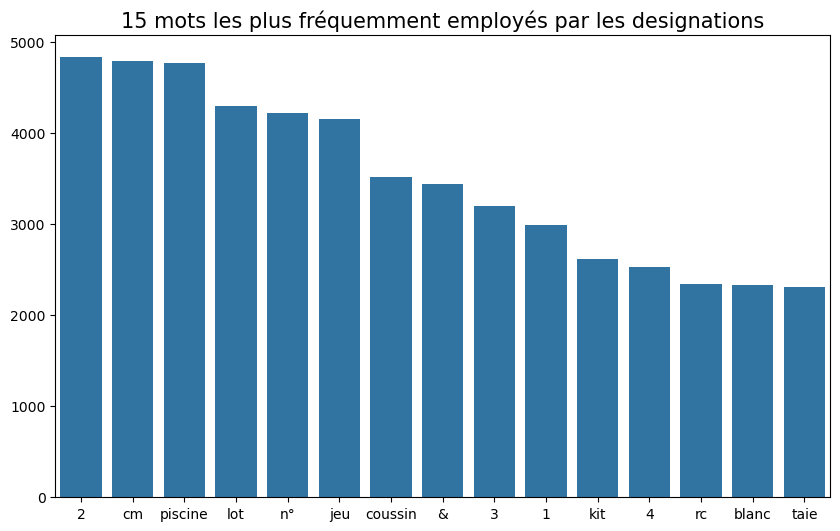

In [164]:
# Nouvelle fréquence des mots après suppression des stopwords
frequency_words(data_train)
print(data_train["designation"].head(10))

## Test mbert pour vectorisation

https://huggingface.co/google-bert/bert-base-multilingual-cased

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')
model = BertModel.from_pretrained("bert-base-multilingual-cased")

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

In [ ]:
X_bert = model.encode(
    data_train['designation'].astype(str).tolist(), 
    batch_size=64, 
    show_progress_bar=True
)